In [1]:
#from mace.calculators import mace_off 
from smilesbox.smilesbox import SMILESbox
from chgnet.model.dynamics import CHGNetCalculator 
from ase.calculators.emt import EMT
from ase.build import sort
from claude_code.nano_reactor import NanoReactor
from claude_code.pathway_enumerator import PathwayEnumerator

from orb_models.forcefield import pretrained
from orb_models.forcefield.inference.calculator import ORBCalculator

Still to do: 

1. make sure they are charged balanced
2. implement templating for sanity checking?

## 1. Forward reaction 

1. build a cell with `SMILESbox` 
2. run a high temperature MD with small time step 
3. Identify viable pathways

In [4]:
smiles = [
    #"O=S=O", "N(=O)[O]","O","[N]=O","OS(=O)(=O)O"

]

smiles = [
    "[N]=O", "O=O","O=S=O", "N(=O)[O]","O","OS(=O)(=O)O"
]
sm = SMILESbox(
    smiles=smiles * 6,
    box_size=20,
    min_distance=0.5
)
atoms = sort(sm.atoms)
print(atoms)
# calculator = CHGNetCalculator(use_device="mps", on_isolated_atoms="ignore")
# calculator = mace_off(model="small")
# calculator = EMT()

orbff, atoms_adapter = pretrained.orb_v3_conservative_inf_omat(
    device="cpu",
    precision="float32-high",   # or "float32-highest" / "float64
)
calculator = ORBCalculator(orbff, atoms_adapter=atoms_adapter, device="cpu")


output_dir = "nanoreactor_forward"
reactor = NanoReactor(
    atoms=atoms,
    calculator=calculator,
    temperature=6000,          # K
    total_time_fs=1000,       # 2 ps
    timestep_fs=0.25,
    tau_min_fs=10,
    reactants={"NO","O2","H2O","NO2","SO2","H2SO4"},
    products={"NO2"},
    output_dir=output_dir,
)

reactor.run()
# reactor.report()
reactor.save_summary_csv(f"{output_dir}/results.csv")
# reactor.plot()
reactor.tracker.summary_dataframe()

Atoms(symbols='H24N12O72S12', pbc=True, cell=[20.0, 20.0, 20.0])


/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/orb_models/common/training/util.py:20: UserWarning: Setting global torch default dtype to torch.float32.
  warnings.warn(f"Setting global torch default dtype to {torch_dtype}.")



NanoReactor starting
  120 atoms | T=6000 K | NVT
  4000 steps × 0.25 fs = 1.0 ps
  τ_min = 10 fs | BO cutoffs = defaults (0.3)
  Output → nanoreactor_forward

Running MD...


/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/ase/md/langevin.py:102: FutureWarning: The implementation of `fixcm=True` in `Langevin` does not strictly sample the correct NVT distributions. The deviations are typically small for large systems but can be more pronounced for small systems. Use `fixcm=False` together with `ase.constraints.FixCom`. `fixcm` is deprecated since ASE 3.28.0 and will be removed in a future release.
  warnings.warn(msg, FutureWarning)


  [SpeciesTracker] processed 500 frames, 13 unique formulae seen
  [SpeciesTracker] processed 1000 frames, 23 unique formulae seen
  [SpeciesTracker] processed 1500 frames, 29 unique formulae seen
  [SpeciesTracker] processed 2000 frames, 30 unique formulae seen
  [SpeciesTracker] processed 2500 frames, 31 unique formulae seen
  [SpeciesTracker] processed 3000 frames, 39 unique formulae seen
  [SpeciesTracker] processed 3500 frames, 40 unique formulae seen
  [SpeciesTracker] processed 4000 frames, 44 unique formulae seen

MD complete in 506.3 s  (126.57 ms/step)

Building reaction network...
[ReactionNetwork] 152 raw transitions → 134 after min_count≥2 filter

[SpeciesTracker] Intermediates passing all filters (τ_min=10 fs, heavy≥2, freq≥0.0%):
  O2S           max_lifetime=1000.2 fs  appearances=29146
  HO2           max_lifetime=480.5 fs  appearances=3242
  H2O4S         max_lifetime=473.8 fs  appearances=6851
  O3S           max_lifetime=426.8 fs  appearances=3552
  HO4S          max

,formula,max_lifetime_fs,total_appearances,n_runs,trajectory_fraction
0,NO,1000.25,24997,1,6.247688
1,NO2,1000.25,18936,1,4.732817
2,O2,1000.25,21754,1,5.437141
3,O2S,1000.25,29146,1,7.284679
4,HO2,480.50,3242,10,0.810297
5,H2O4S,473.75,6851,7,1.712322
6,O3S,426.75,3552,4,0.887778
7,HO4S,339.75,2883,29,0.720570
8,HO3S,252.00,2053,6,0.513122
9,HNO,129.75,614,3,0.153462


In [7]:
reactor.tracker.summary_dataframe().to_excel("test.xlsx")


[SpeciesTracker] Intermediates passing all filters (τ_min=10 fs, heavy≥2, freq≥0.0%):
  NO            max_lifetime=1000.2 fs  appearances=46110
  O2            max_lifetime=1000.2 fs  appearances=22697
  NO3           max_lifetime=59.5 fs  appearances=1100
  N2O4          max_lifetime=40.2 fs  appearances=194
  N2O2          max_lifetime=35.0 fs  appearances=207


In [8]:
enumerator = PathwayEnumerator(
    overall_reaction = "2 NO + O2 = 2 NO2 ",
    md_summary_df    = reactor.tracker.summary_dataframe(
                           reactants={"NO", "O2"},
                           products={"NO2"},
                       ),
)
pathways = enumerator.enumerate()
enumerator.print_pathways(pathways)


[SpeciesTracker] Intermediates passing all filters (τ_min=10 fs, heavy≥2, freq≥0.0%):
  NO3           max_lifetime=59.5 fs  appearances=1100
  N2O4          max_lifetime=40.2 fs  appearances=194
  N2O2          max_lifetime=35.0 fs  appearances=207

Pathway Enumerator
  Overall: 2 NO + O2 = 2 NO2 
  Pool:    ['NO3', 'N2O4', 'N2O2', 'NO', 'O2', 'NO2']
  MD df:   3 species with trajectory data
  Elements: ['N', 'O']

Generating candidate elementary steps...
  20 atom-balanced candidate steps
    2NO -> N2O2
    2NO2 -> N2O2 + O2
    2NO2 -> N2O4
    2NO2 -> NO + NO3
    2NO3 -> N2O4 + O2
    N2O2 + NO3 -> N2O4 + NO
    N2O2 + O2 -> 2NO2
    N2O2 + O2 -> N2O4
    N2O2 + O2 -> NO + NO3
    N2O2 -> 2NO
    N2O4 + NO -> N2O2 + NO3
    N2O4 + O2 -> 2NO3
    N2O4 -> 2NO2
    N2O4 -> N2O2 + O2
    N2O4 -> NO + NO3
    NO + NO3 -> 2NO2
    NO + NO3 -> N2O2 + O2
    NO + NO3 -> N2O4
    NO + O2 -> NO3
    NO3 -> NO + O2

Searching for pathways (ILP)...
  max_step_mult=3  max_path_steps=4  max_pa

## 2. Backward Reaction 

In [ ]:
smiles = [
   "O=NO","[N+](=O)(O)[O-]",
]
sm = SMILESbox(
    smiles = smiles * 2,
    box_size=12,
    min_distance=0.5
)
atoms = sort(sm.atoms)

#calculator = CHGNetCalculator(use_device="mps", on_isolated_atoms="ignore")
#calculator = mace_off(model="small")
calculator = EMT()



output_dir = "nanoreactor_backward"
reactor = NanoReactor(
    atoms        = atoms,
    calculator   = calculator,
    temperature  = 5000,          # K
    total_time_fs= 5000,       # 100 ps
    timestep_fs  = 0.25,
    tau_min_fs   = 100,
    
    reactants    = {"HNO3","HNO2"},
    products     = {"NO2","H2O"},
    output_dir   = output_dir,
)

reactor.run()
#reactor.report()
reactor.save_summary_csv(f"{output_dir}/results.csv")
#reactor.plot()
reactor.tracker.summary_dataframe()


NanoReactor starting
  18 atoms | T=5000 K | NVT
  20000 steps × 0.25 fs = 5.0 ps
  τ_min = 100 fs | BO cutoffs = defaults (0.3)
  Output → nanoreactor_backward

Running MD...


/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/ase/md/langevin.py:102: FutureWarning: The implementation of `fixcm=True` in `Langevin` does not strictly sample the correct NVT distributions. The deviations are typically small for large systems but can be more pronounced for small systems. Use `fixcm=False` together with `ase.constraints.FixCom`. `fixcm` is deprecated since ASE 3.28.0 and will be removed in a future release.
  warnings.warn(msg, FutureWarning)


  [SpeciesTracker] processed 500 frames, 9 unique formulae seen
  [SpeciesTracker] processed 1000 frames, 11 unique formulae seen
  [SpeciesTracker] processed 1500 frames, 14 unique formulae seen
  [SpeciesTracker] processed 2000 frames, 14 unique formulae seen
  [SpeciesTracker] processed 2500 frames, 22 unique formulae seen
  [SpeciesTracker] processed 3000 frames, 22 unique formulae seen
  [SpeciesTracker] processed 3500 frames, 23 unique formulae seen
  [SpeciesTracker] processed 4000 frames, 27 unique formulae seen
  [SpeciesTracker] processed 4500 frames, 30 unique formulae seen
  [SpeciesTracker] processed 5000 frames, 31 unique formulae seen
  [SpeciesTracker] processed 5500 frames, 31 unique formulae seen
  [SpeciesTracker] processed 6000 frames, 31 unique formulae seen
  [SpeciesTracker] processed 6500 frames, 31 unique formulae seen
  [SpeciesTracker] processed 7000 frames, 31 unique formulae seen
  [SpeciesTracker] processed 7500 frames, 33 unique formulae seen
  [SpeciesTr

,formula,max_lifetime_fs,total_appearances,n_runs,trajectory_fraction
0,NO,745.25,33446,17,1.672216
1,O2,734.50,22014,86,1.100645
2,NO2,480.00,10014,47,0.500675
3,O3,351.25,5685,92,0.284236
4,N2O,211.50,4015,18,0.200740


In [ ]:
enumerator = PathwayEnumerator(
    overall_reaction = "2 NO2 + H2O = HNO2 + HNO3",
    md_summary_df    = reactor.tracker.summary_dataframe(
                           reactants={"HNO2", "HNO3"},
                           products={"NO2","H2O"},
                       ),
)
pathways = enumerator.enumerate()
enumerator.print_pathways(pathways)


[SpeciesTracker] Intermediates passing all filters (τ_min=100 fs, heavy≥2, freq≥0.0%):
  NO            max_lifetime=745.2 fs  appearances=33446
  O2            max_lifetime=734.5 fs  appearances=22014
  O3            max_lifetime=351.2 fs  appearances=5685
  N2O           max_lifetime=211.5 fs  appearances=4015

Pathway Enumerator
  Overall: 2 NO2 + H2O = HNO2 + HNO3
  Pool:    ['NO', 'O2', 'O3', 'N2O', 'NO2', 'H2O', 'HNO2', 'HNO3']
  MD df:   4 species with trajectory data
  Elements: ['H', 'N', 'O']

Generating candidate elementary steps...
  10 atom-balanced candidate steps
    2NO2 -> N2O + O3
    HNO2 + NO2 -> HNO3 + NO
    HNO2 + O3 -> HNO3 + O2
    HNO3 + NO -> HNO2 + NO2
    HNO3 + O2 -> HNO2 + O3
    N2O + O2 -> NO + NO2
    N2O + O3 -> 2NO2
    NO + NO2 -> N2O + O2
    NO + O3 -> NO2 + O2
    NO2 + O2 -> NO + O3

Searching for pathways (ILP)...
  max_step_mult=3  max_path_steps=4  max_paths=20

  Found 0 valid pathways.
  Ranked by MD trajectory evidence.

PATHWAYS for:  2 N

In [ ]:
Boltzmann * 298 / h

6209312498751.617

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import e, Boltzmann, R, h

eas = np.linspace(1e-10, 5, int((500/100)))
Ts = np.arange(0,500,100)

def eyring(ea, T):
    preexp = (Boltzmann * T) / h
    return preexp, preexp * np.exp(- ((ea) / (Boltzmann/e * T)))


import itertools as it 
from collections import defaultdict

eyrings = defaultdict(dict)
preexps = defaultdict(dict)
for ea,t in list(it.product(eas,Ts)):
    p,ey = eyring(ea,t)
    preexps[ea][t] = p
    eyrings[ea][t] = ey

dfey = pd.DataFrame(eyrings)
dfp = pd.DataFrame(preexps)

/var/folders/40/xmstzxyn7377k__pn0yxn6w80000gn/T/ipykernel_27268/3086543411.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  return preexp, preexp * np.exp(- ((ea) / (Boltzmann/e * T)))


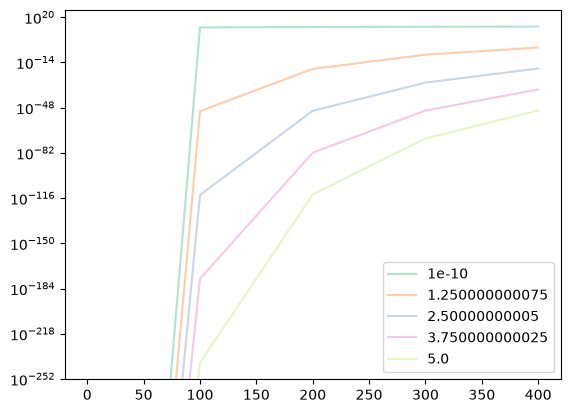

In [ ]:
ax=dfey.plot.line()
ax.set_yscale("log")


<Axes: >

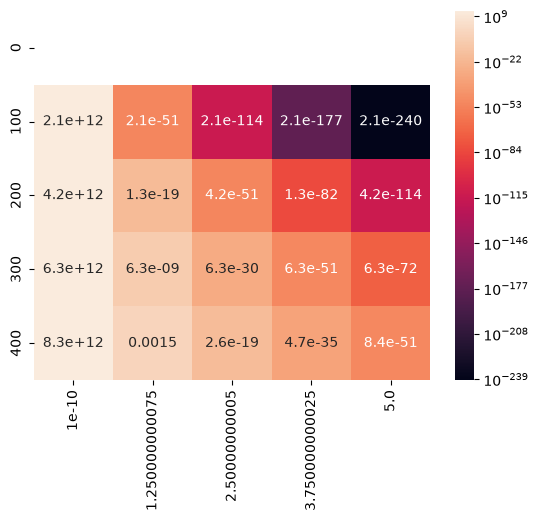

In [ ]:
sns.heatmap(dfey,annot=True,norm="log")

ValueError: `data` and `annot` must have same shape.

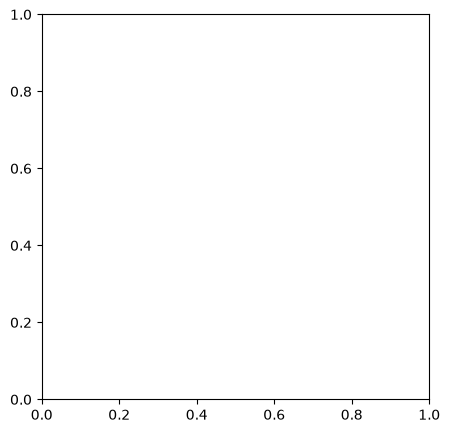

In [ ]:
fig,axes = plt.subplots(1,1,figsize=(5,5),dpi=100)
import seaborn as sns 
sns.set_palette("Pastel2")


sns.heatmap(data=dfey,norm="log",annot="True")


In [ ]:
dfey

,1.000000e-10,2.500000e-01,5.000000e-01,7.500000e-01,1.000000e+00
0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
100,2.083662e+12,5.240609e-01,1.318063e-13,3.315056e-26,8.337683e-39
200,4.167324e+12,2.089943e+06,1.048122e+00,5.256408e-07,2.636127e-13
300,6.250986e+12,3.945784e+08,2.490682e+04,1.572183e+00,9.924026e-05
400,8.334648e+12,5.902362e+09,4.179887e+06,2.960078e+03,2.096244e+00
